<a href="https://colab.research.google.com/github/VINIXX06/Mini-Project-Machine-Learning-I-Smile-/blob/main/Copy_of_Kelompok_04_Potensi_Obesitas_Berdasarkan_Frekuensi_Aktivitas_Fisik.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project Study Group I-Smile: EDA to Machine Learning
## **Prediksi Potensi Obesitas Berdasarkan Frekuensi Aktivitas Fisik**

**Laboratorium I-Smile · Program Studi S1 Teknik Komputer, Telkom University**  
**Kelompok 04 (Asisten Pendamping: TIM)**
1. **Rifky Ghassan Suhail** — NIM: `101032400034` (Kelas TK-48-03)
2. **Ilham Kholid** — NIM: `101032430033` (Kelas TK-48-03)
3. **Dimas Rasya Nayottama** — NIM: `101032400065` (Kelas TK-48-03)

---

### 1. Rumusan Masalah & Tujuan Proyek
- **Pertanyaan Utama:** *Seberapa akurat kita dapat memprediksi potensi obesitas seseorang menggunakan algoritma K-Nearest Neighbors (`KNN`) berdasarkan frekuensi aktivitas fisik (`FAF`) serta kebiasaan gaya hidup sehari-hari (tanpa mengukur berat dan tinggi badan secara langsung)?*
- **Kolom Target:** `NObeyesdad` (tingkat berat badan 7 kategori), yang ditransformasikan menjadi **target biner `target`** (`1 = Obesitas` untuk *Obesity Type I, II, III*; `0 = Tidak Obesitas` untuk *Insufficient Weight, Normal Weight, Overweight Level I & II*), sesuai pendekatan klasifikasi medis pada Materi Hari 3.
- **Jenis Masalah & Model Standar Wajib:** **Klasifikasi Biner** dengan model standar wajib **`KNeighborsClassifier` + `StandardScaler`**, serta dibandingkan dengan **`Decision Tree`** dan **`Random Forest`** sesuai materi Study Group Hari 3 & Hari 4.
- **Mengapa Memakai KNN dan Bukan Regresi Linear (`LinearRegression`)?**
  1. **Target Berupa Kategori, Bukan Angka Kontinu (Materi Hari 3 Slide 5):** Regresi Linear (`Hari 2`) hanya digunakan untuk masalah **regresi** yang menebak angka kontinu (seperti harga rumah dalam USD) dan diukur dari besar selisih (`MAE`, `RMSE`, `R²`). Pada proyek ini, kolom target `NObeyesdad` / `target` adalah **kategori kelas** (`0 = Tidak Obesitas` vs `1 = Obesitas`) yang dinilai benar atau salah, sehingga termasuk masalah **klasifikasi** yang menurut Brief Mini Project wajib memakai **`KNeighborsClassifier` dengan scaling**.
  2. **Keterbatasan Rentang Prediksi Regresi Linear (Materi Hari 2 Slide 19):** Garis lurus pada Regresi Linear ($\hat{y} = b_0 + b_1 x_1 + \dots$) tidak memiliki batas rentang, sehingga bisa menebak angka desimal di luar `0` dan `1` (misalnya `-0,25` atau `1,35`) yang tidak bermakna untuk status obesitas.
  3. **Pola Kemiripan Gaya Hidup Bersifat Non-Linear:** Hubungan frekuensi aktivitas fisik (`FAF`), moda transportasi (`MTRANS`), dan pola makan terhadap obesitas tidak berbentuk satu garis lurus, melainkan pengelompokan individu dengan kebiasaan hidup serupa yang sangat cocok ditebak melalui *voting* $k$ tetangga terdekat pada **KNN**.
- **Pengguna Hasil (*User*):** Klinik kesehatan kampus (seperti Telkomedika), Puskesmas, penyuluh kesehatan masyarakat, dan aplikasi kebugaran mandiri (*wellness pre-screening*) untuk menjaring individu berisiko obesitas sejak dini melalui kuesioner kebiasaan hidup sebelum pemeriksaan klinis lanjutan.
- **Metrik Evaluasi Utama:** **Recall**, **Accuracy**, **Precision**, dan **Confusion Matrix**. Dalam konteks skrining kesehatan, kesalahan **False Negative (FN)** (orang yang mengalami obesitas tetapi ditebak tidak obesitas) jauh lebih merugikan karena membuat penderita luput dari intervensi olahraga dan diet dini.

### 2. Sumber & Tautan Dataset
- **Nama Dataset:** *Estimation of Obesity Levels Based On Eating Habits and Physical Condition* (`ObesityDataSet.csv`, 2.111 baris × 17 kolom).
- **Tautan Kaggle (Pengajuan Kelompok 04 - Disetujui):** [Kaggle — Obesity or CVD Risk (Classify/Regressor/Cluster)](https://www.kaggle.com/datasets/aravindpcoder/obesity-or-cvd-risk-classifyregressorcluster/data)
- **Tautan Asli UCI Machine Learning Repository:** [UCI ML Repository — Estimation of Obesity Levels (ID 544)](https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition)
- **Tautan Google Drive Kelompok 04:** [Google Sheets/Drive — ObesityDataSet.csv](https://docs.google.com/spreadsheets/d/1vZnec_cVUqI3FYdB20RBrR7qVpYSaN2MFqK8UsjfRsc/edit?usp=sharing)

In [ ]:

display(df.head())

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


---
## 0. Persiapan Library dan Pemuatan Dataset
Kita mengimpor pustaka pengolahan data (`pandas`, `numpy`), visualisasi (`matplotlib`, `seaborn`), serta pemodelan dan evaluasi dari `scikit-learn` sesuai materi Hari 1 sampai Hari 4.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd               # mengolah tabel (DataFrame)
import numpy as np                # operasi numerik dan array
import matplotlib.pyplot as plt   # membuat visualisasi grafik
import seaborn as sns             # membuat heatmap korelasi

# Pembagian data, validasi silang (5-fold CV), dan pencarian parameter terbaik
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline                        # membungkus scaler + model agar bebas data leakage
from sklearn.preprocessing import StandardScaler, MinMaxScaler    # menyamakan skala fitur numerik (Hari 3)
from sklearn.neighbors import KNeighborsClassifier                # MODEL UTAMA WAJIB: KNN untuk klasifikasi
from sklearn.tree import DecisionTreeClassifier, plot_tree        # model tambahan pembanding: Decision Tree
from sklearn.ensemble import RandomForestClassifier               # model tambahan pembanding: Random Forest
from sklearn.metrics import (                                     # metrik wajib klasifikasi (Hari 3 & 4)
    accuracy_score, precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)  # tampilkan seluruh kolom saat mencetak tabel
plt.rcParams["figure.figsize"] = (8.5, 4.8) # ukuran bawaan grafik
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

Dataset dimuat secara otomatis dari tautan di dalam notebook sehingga dapat langsung menjalankan **Runtime → Run all** di Google Colab tanpa perlu mengunggah berkas secara manual.

In [ ]:
# PEMUATAN DATASET MENTAH ASLI KAGGLE (2.111 baris x 17 kolom — BELUM DIUBAH SAMA SEKALI)
# Seluruh proses pembersihan (hapus duplikat, buang Height/Weight, target biner, & encoding)
# dilakukan di dalam sel-sel notebook ini pada Tahap 2 (Data Cleaning).
import os, glob

KAGGLE_DATASET_SLUG = "aravindpcoder/obesity-or-cvd-risk-classifyregressorcluster"
DRIVE_CSV_URL = "https://docs.google.com/spreadsheets/d/1vZnec_cVUqI3FYdB20RBrR7qVpYSaN2MFqK8UsjfRsc/export?format=csv"
PUBLIC_RAW_URL = "https://raw.githubusercontent.com/pymche/Machine-Learning-Obesity-Classification/master/ObesityDataSet_raw_and_data_sinthetic.csv"

df = None
# 1. Cek jika panitia menaruh file CSV asli hasil unduhan Kaggle di direktori kerja Colab
for nama_lokal in ["ObesityDataSet.csv", "ObesityDataSet_raw_and_data_sinthetic.csv"]:
    if os.path.exists(nama_lokal):
        df = pd.read_csv(nama_lokal)
        print(f"Dataset mentah asli dimuat dari berkas lokal Kaggle: {nama_lokal}")
        break

# 2. Jika belum ada di lokal, unduh otomatis dari tautan publik / Google Drive / kagglehub
if df is None:
    for sumber, url in [("Tautan Publik Kaggle/UCI", PUBLIC_RAW_URL), ("Google Drive Kelompok 04", DRIVE_CSV_URL)]:
        try:
            df_cand = pd.read_csv(url)
            if df_cand.shape == (2111, 17):
                df = df_cand
                print(f"Dataset mentah asli berhasil dimuat dari: {sumber}")
                break
        except Exception:
            continue

if df is None:
    import kagglehub
    path_unduh = kagglehub.dataset_download(KAGGLE_DATASET_SLUG)
    berkas_csv = glob.glob(os.path.join(path_unduh, "*.csv"))[0]
    df = pd.read_csv(berkas_csv)
    print(f"Dataset mentah asli diunduh via kagglehub: {berkas_csv}")

assert df.shape == (2111, 17), f"Ukuran data {df.shape}, seharusnya data mentah asli (2111, 17)."
print("Ukuran dataset mentah awal (belum diubah):", df.shape)
print("Jumlah kolom teks asli (belum di-encoding):", len(df.select_dtypes(include="object").columns), "kolom")
df.head()

Dataset mentah asli dimuat dari berkas lokal Kaggle: ObesityDataSet.csv
Ukuran dataset mentah awal (belum diubah): (2111, 17)
Jumlah kolom teks asli (belum di-encoding): 9 kolom


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


### Kamus Kolom (`1 baris = 1 responden/individu`)
| No | Kolom | Arti / Pertanyaan Survei | Tipe Data | Kategori / Rentang Nilai |
|---|---|---|---|---|
| 1 | `Gender` | Jenis kelamin responden | Kategorik (Teks) | `Female`, `Male` |
| 2 | `Age` | Umur responden (tahun) | Numerik | `14,0` – `61,0` tahun |
| 3 | `Height` | Tinggi badan responden (meter) | Numerik | `1,45` – `1,98` m *(Pembentuk rumus BMI)* |
| 4 | `Weight` | Berat badan responden (kilogram) | Numerik | `39,0` – `173,0` kg *(Pembentuk rumus BMI)* |
| 5 | `family_history_with_overweight` | Apakah ada anggota keluarga yang kelebihan berat badan? | Kategorik (Biner) | `yes`, `no` |
| 6 | `FAVC` | Apakah sering mengonsumsi makanan tinggi kalori (*Frequent High Caloric Food*)? | Kategorik (Biner) | `yes`, `no` |
| 7 | `FCVC` | Frekuensi makan sayur dalam makanan utama (*Frequency of Vegetables*) | Numerik (Skala) | `1` (tidak pernah) – `3` (selalu) |
| 8 | `NCP` | Jumlah makan utama per hari (*Number of Main Meals*) | Numerik (Skala) | `1` – `4` kali sehari |
| 9 | `CAEC` | Kebiasaan makan camilan di antara waktu makan utama (*Consumption of Food Between Meals*) | Kategorik (Teks) | `no`, `Sometimes`, `Frequently`, `Always` |
| 10 | `SMOKE` | Apakah responden merokok? | Kategorik (Biner) | `yes`, `no` |
| 11 | `CH2O` | Konsumsi air minum harian (*Consumption of Water Daily*) | Numerik (Skala) | `1` (< 1 liter), `2` (1–2 liter), `3` (> 2 liter) |
| 12 | `SCC` | Apakah memantau asupan kalori harian (*Calories Consumption Monitoring*)? | Kategorik (Biner) | `yes`, `no` |
| 13 | **`FAF`** | **Frekuensi aktivitas fisik / olahraga per minggu (*Physical Activity Frequency*)** | **Numerik (Skala)** | **`0` (tidak pernah), `1` (1–2 hari), `2` (2–4 hari), `3` (4–5 hari)** |
| 14 | `TUE` | Waktu penggunaan perangkat teknologi/gawai per hari (*Time Using Technology Devices*) | Numerik (Skala) | `0` (0–2 jam), `1` (3–5 jam), `2` (> 5 jam) |
| 15 | `CALC` | Frekuensi konsumsi alkohol (*Consumption of Alcohol*) | Kategorik (Teks) | `no`, `Sometimes`, `Frequently`, `Always` |
| 16 | `MTRANS` | Moda transportasi utama yang dipakai sehari-hari | Kategorik (Teks) | `Public_Transportation`, `Automobile`, `Walking`, `Motorbike`, `Bike` |
| 17 | **`NObeyesdad`** | **Tingkat obesitas responden (Kolom Target)** | **Kategorik (Target)** | 7 kelas tingkat berat badan |

---
# Tahap 1: Exploratory Data Analysis (EDA)
Tujuan EDA adalah mengenali struktur tipe data, memeriksa distribusi target, menemukan potensi masalah data (seperti perbedaan skala fitur pada KNN atau **kebocoran target**), serta memetakan hubungan antara **frekuensi aktivitas fisik (`FAF`)** dan kebiasaan gaya hidup terhadap potensi obesitas.

### 1a. Ringkasan Struktur Data (`info`) dan Statistik Deskriptif (`describe`)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

In [ ]:
df.describe().round(2)

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.00,2111.00,2111.00,2111.00,2111.00,2111.00,2111.00,2111.00
mean,24.31,1.70,86.59,2.42,2.69,2.01,1.01,0.66
std,6.35,0.09,26.19,0.53,0.78,0.61,0.85,0.61
min,14.00,1.45,39.00,1.00,1.00,1.00,0.00,0.00
25%,19.95,1.63,65.47,2.00,2.66,1.58,0.12,0.00
50%,22.78,1.70,83.00,2.39,3.00,2.00,1.00,0.63
75%,26.00,1.77,107.43,3.00,3.00,2.48,1.67,1.00
max,61.00,1.98,173.00,3.00,4.00,3.00,3.00,2.00


**Temuan Awal dari `info()` dan `describe()`:**
1. Seluruh 17 kolom memiliki **2.111 nilai non-null** (tidak ada nilai kosong) dan nilai minimum seluruh kolom wajar secara medis (tidak ada *missing tersamar*).
2. Perhatikan perbedaan skala antar kolom numerik: `Age` memiliki rentang `14`–`61` (standar deviasi `6,35`), sedangkan `FAF` hanya berentang `0`–`3` (standar deviasi `0,85`). Perbedaan skala hampir **8 kali lipat** ini membuktikan bahwa **model utama KNN wajib menggunakan *feature scaling* (`StandardScaler`)** agar perhitungan jarak Euclidean tidak didominasi oleh umur (`Age`).

### 1b. Distribusi Target (`NObeyesdad` dan Transformasi Target Biner)

In [ ]:
dist_target = pd.DataFrame({
    "Jumlah Responden": df["NObeyesdad"].value_counts(),
    "Persentase (%)": (df["NObeyesdad"].value_counts(normalize=True) * 100).round(2)
})
dist_target

,Jumlah Responden,Persentase (%)
NObeyesdad,,
Obesity_Type_I,351,16.63
Obesity_Type_III,324,15.35
Obesity_Type_II,297,14.07
Overweight_Level_I,290,13.74
Overweight_Level_II,290,13.74
Normal_Weight,287,13.60
Insufficient_Weight,272,12.88


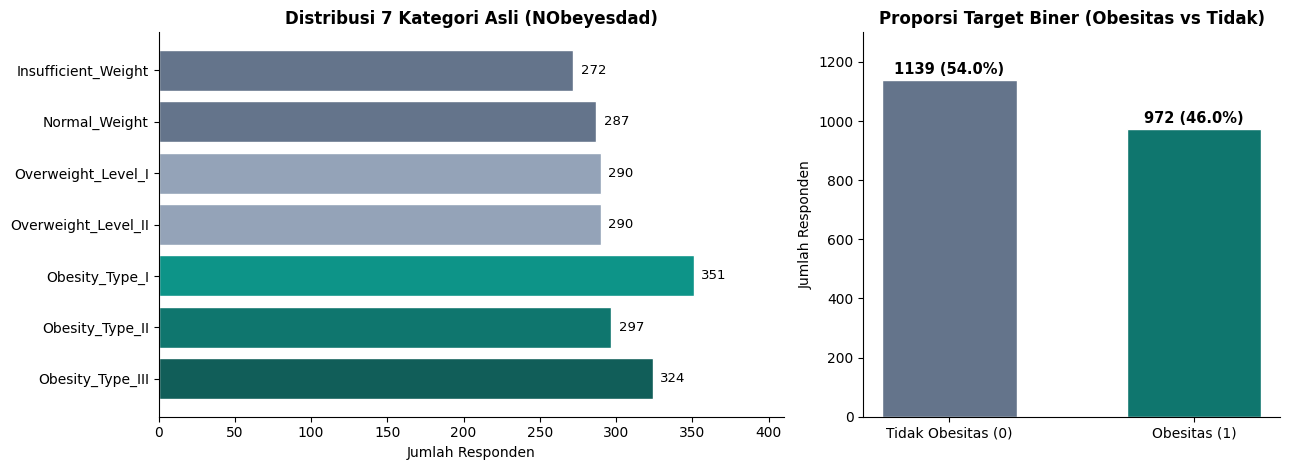

In [ ]:
# Visualisasi 1: Distribusi 7 Kategori Asli vs Target Biner (Obesitas vs Tidak Obesitas)
urutan_7 = [
    "Insufficient_Weight", "Normal_Weight", "Overweight_Level_I", "Overweight_Level_II",
    "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"
]
hitung_7 = df["NObeyesdad"].value_counts().reindex(urutan_7)
warna_7 = ["#64748b", "#64748b", "#94a3b8", "#94a3b8", "#0d9488", "#0f766e", "#115e59"]

status_biner = df["NObeyesdad"].str.startswith("Obesity").map({False: "Tidak Obesitas (0)", True: "Obesitas (1)"})
hitung_biner = status_biner.value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})

bars1 = axes[0].barh(urutan_7, hitung_7.values, color=warna_7, edgecolor="white")
axes[0].set_title("Distribusi 7 Kategori Asli (NObeyesdad)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Jumlah Responden")
axes[0].invert_yaxis()
for bar in bars1:
    w = bar.get_width()
    axes[0].text(w + 5, bar.get_y() + bar.get_height()/2, f"{int(w)}", va="center", fontsize=9.5)
axes[0].set_xlim(0, 410)

bars2 = axes[1].bar(hitung_biner.index, hitung_biner.values, color=["#64748b", "#0f766e"], width=0.55, edgecolor="white")
axes[1].set_title("Proporsi Target Biner (Obesitas vs Tidak)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Jumlah Responden")
for bar in bars2:
    h = bar.get_height()
    pct = h / len(df) * 100
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 20, f"{int(h)} ({pct:.1f}%)", ha="center", fontweight="bold", fontsize=10.5)
axes[1].set_ylim(0, 1300)

plt.tight_layout()
plt.show()

**Temuan Visualisasi 1 (Distribusi Target):**
Ketika dikelompokkan menjadi target biner sesuai Materi Hari 3 (`1 = Obesitas` [Tipe I, II, III] vs `0 = Tidak Obesitas` [Insufficient, Normal, Overweight I & II]), terdapat **972 responden Obesitas (`46,0%`)** dan **1.139 responden Tidak Obesitas (`54,0%`)**. Proporsi yang seimbang ini ideal untuk KNN, dan akan dijaga dengan `stratify=y` saat pembagian data.

### 1c. Visualisasi 2: Hubungan Frekuensi Aktivitas Fisik (`FAF`) dengan Tingkat Obesitas

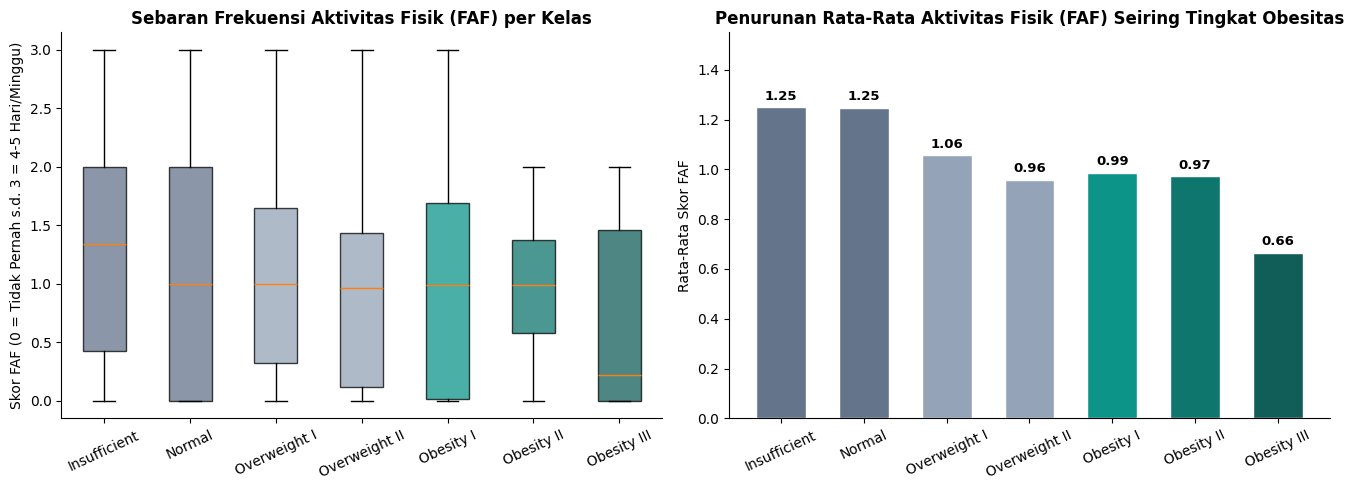

Rata-rata FAF pada kelompok Tidak Obesitas (0): 1.13
Rata-rata FAF pada kelompok Obesitas (1)      : 0.87


In [ ]:
# Visualisasi 2: Boxplot dan Rata-rata Frekuensi Aktivitas Fisik (FAF) per Kategori Berat Badan
data_faf_per_kelas = [df.loc[df["NObeyesdad"] == k, "FAF"] for k in urutan_7]
rata_faf_per_kelas = [df.loc[df["NObeyesdad"] == k, "FAF"].mean() for k in urutan_7]
label_pendek = ["Insufficient", "Normal", "Overweight I", "Overweight II", "Obesity I", "Obesity II", "Obesity III"]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

bp = axes[0].boxplot(data_faf_per_kelas, patch_artist=True, labels=label_pendek)
for patch, color in zip(bp["boxes"], warna_7):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
axes[0].set_title("Sebaran Frekuensi Aktivitas Fisik (FAF) per Kelas", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Skor FAF (0 = Tidak Pernah s.d. 3 = 4-5 Hari/Minggu)")
axes[0].tick_params(axis="x", rotation=25)

bars = axes[1].bar(label_pendek, rata_faf_per_kelas, color=warna_7, edgecolor="white", width=0.6)
axes[1].set_title("Penurunan Rata-Rata Aktivitas Fisik (FAF) Seiring Tingkat Obesitas", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Rata-Rata Skor FAF")
axes[1].tick_params(axis="x", rotation=25)
axes[1].set_ylim(0, 1.55)
for bar, val in zip(bars, rata_faf_per_kelas):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.03, f"{val:.2f}", ha="center", fontweight="bold", fontsize=9.5)

plt.tight_layout()
plt.show()

print("Rata-rata FAF pada kelompok Tidak Obesitas (0):", round(df.loc[~df["NObeyesdad"].str.startswith("Obesity"), "FAF"].mean(), 2))
print("Rata-rata FAF pada kelompok Obesitas (1)      :", round(df.loc[df["NObeyesdad"].str.startswith("Obesity"), "FAF"].mean(), 2))

**Temuan Visualisasi 2 (Frekuensi Aktivitas Fisik `FAF` vs Obesitas):**
Rata-rata skor `FAF` menurun secara konsisten dari **1,25** pada `Normal_Weight` menjadi **0,99** (`Obesity_Type_I`), **0,97** (`Obesity_Type_II`), hingga **anjlok ke 0,66 (median 0,22) pada `Obesity_Type_III`**. Namun, karena rentang kuartil pada boxplot masih saling beririsan, `FAF` perlu dikombinasikan dengan fitur gaya hidup lain di dalam perhitungan jarak tetangga KNN.

### 1d. Visualisasi 3: Peran Moda Transportasi Harian (`MTRANS`) & Interaksi Riwayat Keluarga + Kalori (`FAVC`)

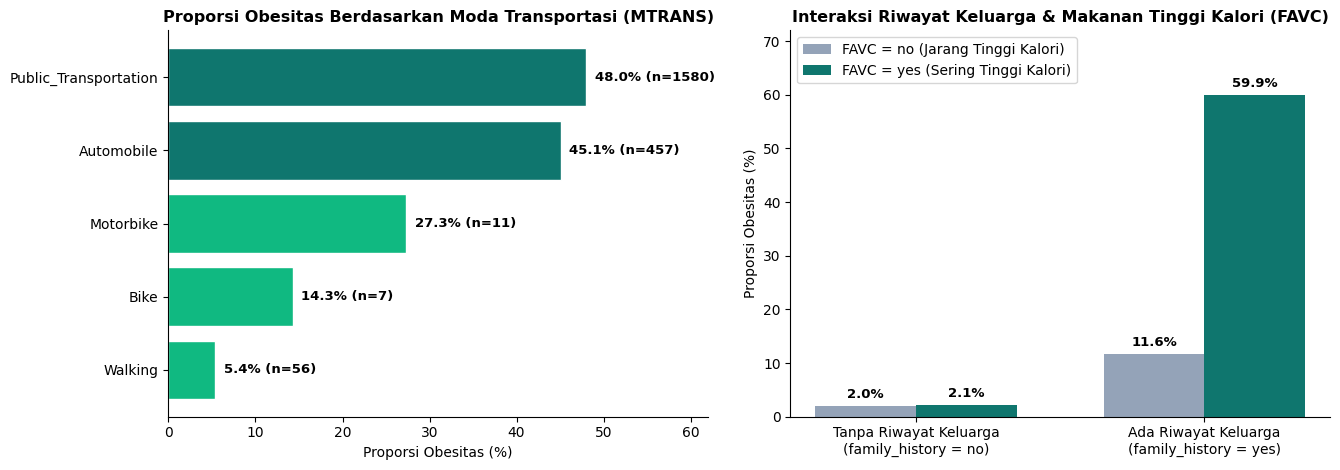

In [ ]:
# Visualisasi 3: Proporsi Obesitas berdasarkan Moda Transportasi (MTRANS) dan Riwayat Keluarga / FAVC
df_temp = df.copy()
df_temp["is_obese"] = df_temp["NObeyesdad"].str.startswith("Obesity").astype(int) * 100

mtrans_rate = df_temp.groupby("MTRANS")["is_obese"].agg(["count", "mean"]).sort_values("mean", ascending=True)
fam_favc_rate = df_temp.groupby(["family_history_with_overweight", "FAVC"])["is_obese"].mean().unstack()

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

warna_mtrans = ["#10b981" if m < 30 else "#0f766e" for m in mtrans_rate["mean"]]
bars_m = axes[0].barh(mtrans_rate.index, mtrans_rate["mean"], color=warna_mtrans, edgecolor="white")
axes[0].set_title("Proporsi Obesitas Berdasarkan Moda Transportasi (MTRANS)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("Proporsi Obesitas (%)")
axes[0].set_xlim(0, 62)
for bar, (_, row) in zip(bars_m, mtrans_rate.iterrows()):
    axes[0].text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
                 f"{row['mean']:.1f}% (n={int(row['count'])})", va="center", fontsize=9.5, fontweight="bold")

x_pos = np.arange(2)
w = 0.35
b1 = axes[1].bar(x_pos - w/2, fam_favc_rate["no"], width=w, label="FAVC = no (Jarang Tinggi Kalori)", color="#94a3b8")
b2 = axes[1].bar(x_pos + w/2, fam_favc_rate["yes"], width=w, label="FAVC = yes (Sering Tinggi Kalori)", color="#0f766e")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(["Tanpa Riwayat Keluarga\n(family_history = no)", "Ada Riwayat Keluarga\n(family_history = yes)"])
axes[1].set_ylabel("Proporsi Obesitas (%)")
axes[1].set_title("Interaksi Riwayat Keluarga & Makanan Tinggi Kalori (FAVC)", fontsize=11.5, fontweight="bold")
axes[1].set_ylim(0, 72)
axes[1].legend(loc="upper left")
for bar in list(b1) + list(b2):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 1.5, f"{h:.1f}%", ha="center", fontweight="bold", fontsize=9.5)

plt.tight_layout()
plt.show()

**Temuan Visualisasi 3 (Transportasi Aktif & Interaksi Gaya Hidup):**
Responden yang berjalan kaki (`Walking`, n=56) hanya memiliki tingkat obesitas **`5,4%`** dan pengguna sepeda (`Bike`, n=7) **`14,3%`**, sedangkan pengguna transportasi umum (**`48,0%`**) dan mobil pribadi (**`45,1%`**) hampir **9 kali lebih berisiko**. Selain itu, kombinasi riwayat keluarga + makanan tinggi kalori (`FAVC = yes`) mendorong proporsi obesitas ke **`59,9%`**.

### 1e. Visualisasi 4 & 5: Deteksi Kebocoran Target (`Height` & `Weight`) serta Heatmap Korelasi

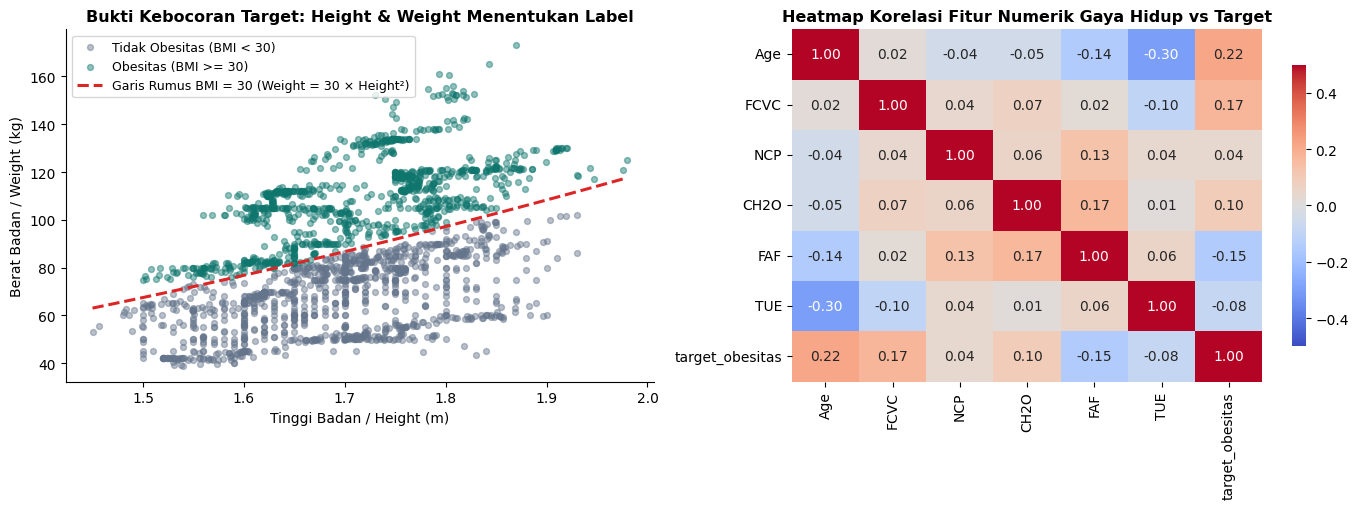

In [ ]:
# Visualisasi 4 & 5: Scatter Plot Height vs Weight (Deteksi Target Leakage BMI) dan Heatmap Korelasi
df_corr = df.copy()
df_corr["target_obesitas"] = df_corr["NObeyesdad"].str.startswith("Obesity").astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

bukan_ob = df_corr[df_corr["target_obesitas"] == 0]
ya_ob = df_corr[df_corr["target_obesitas"] == 1]
axes[0].scatter(bukan_ob["Height"], bukan_ob["Weight"], alpha=0.45, s=18, color="#64748b", label="Tidak Obesitas (BMI < 30)")
axes[0].scatter(ya_ob["Height"], ya_ob["Weight"], alpha=0.45, s=18, color="#0f766e", label="Obesitas (BMI >= 30)")

h_grid = np.linspace(1.45, 1.98, 100)
axes[0].plot(h_grid, 30 * (h_grid ** 2), color="#dc2626", linestyle="--", linewidth=2.2, label="Garis Rumus BMI = 30 (Weight = 30 × Height²)")
axes[0].set_title("Bukti Kebocoran Target: Height & Weight Menentukan Label", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("Tinggi Badan / Height (m)")
axes[0].set_ylabel("Berat Badan / Weight (kg)")
axes[0].legend(loc="upper left", fontsize=9)

kolom_num_bersih = ["Age", "FCVC", "NCP", "CH2O", "FAF", "TUE", "target_obesitas"]
matriks_korelasi = df_corr[kolom_num_bersih].corr()
sns.heatmap(matriks_korelasi, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.5, vmax=0.5, center=0, ax=axes[1], cbar_kws={"shrink": 0.8})
axes[1].set_title("Heatmap Korelasi Fitur Numerik Gaya Hidup vs Target", fontsize=11.5, fontweight="bold")

plt.tight_layout()
plt.show()

**Temuan Visualisasi 4 & 5 (Kebocoran Target & Korelasi Numerik):**
Garis merah putus-putus ($\text{Weight} = 30 \times \text{Height}^2$) memisahkan kelas Obesitas dan Tidak Obesitas secara sempurna karena label `NObeyesdad` diturunkan langsung dari rumus $\text{BMI} = \text{Weight}/\text{Height}^2 \ge 30$. Sesuai daftar periksa **Brief Mini Project (Halaman 2: *Kebocoran Target*)**, **`Weight` dan `Height` wajib dikeluarkan dari fitur `X`** agar KNN benar-benar mencari kemiripan berdasarkan **frekuensi aktivitas fisik (`FAF`) dan kebiasaan gaya hidup**.

---
# Tahap 2: Data Cleaning & Preprocessing untuk KNN
Seluruh proses pembersihan dilakukan pada salinan tabel `df_clean = df.copy()` agar data mentah `df` tetap utuh.

In [ ]:
df_clean = df.copy()
print("Ukuran awal df_clean:", df_clean.shape)
print("Total missing value :", df_clean.isnull().sum().sum())
print("Baris duplikat awal :", df_clean.duplicated().sum())

Ukuran awal df_clean: (2111, 17)
Total missing value : 0
Baris duplikat awal : 24


In [ ]:
# Hapus 24 baris duplikat untuk mencegah data leakage antara data latih dan data uji
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Ukuran df_clean setelah hapus duplikat:", df_clean.shape)
print("Sisa baris duplikat                   :", df_clean.duplicated().sum())

Ukuran df_clean setelah hapus duplikat: (2087, 17)
Sisa baris duplikat                   : 0


### 2c. Pemeriksaan Outlier dengan Metode IQR

In [ ]:
kolom_numerik = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]
ringkasan_outlier = []

for kol in kolom_numerik:
    Q1 = df_clean[kol].quantile(0.25)
    Q3 = df_clean[kol].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR
    jml_out = ((df_clean[kol] < batas_bawah) | (df_clean[kol] > batas_atas)).sum()
    ringkasan_outlier.append({
        "Kolom": kol,
        "Min": df_clean[kol].min(),
        "Q1": Q1,
        "Median": df_clean[kol].median(),
        "Q3": Q3,
        "Max": df_clean[kol].max(),
        "Batas Bawah": batas_bawah,
        "Batas Atas": batas_atas,
        "Jumlah Outlier": jml_out
    })

pd.DataFrame(ringkasan_outlier).round(2)

,Kolom,Min,Q1,Median,Q3,Max,Batas Bawah,Batas Atas,Jumlah Outlier
0,Age,14.00,19.92,22.85,26.00,61.00,10.79,35.13,167
1,Height,1.45,1.63,1.70,1.77,1.98,1.42,1.98,1
2,Weight,39.00,66.00,83.10,108.02,173.00,2.98,171.04,1
3,FCVC,1.00,2.00,2.40,3.00,3.00,0.50,4.50,0
4,NCP,1.00,2.70,3.00,3.00,4.00,2.24,3.45,577
5,CH2O,1.00,1.59,2.00,2.47,3.00,0.28,3.78,0
6,FAF,0.00,0.12,1.00,1.68,3.00,-2.21,4.01,0
7,TUE,0.00,0.00,0.63,1.00,2.00,-1.50,2.50,0


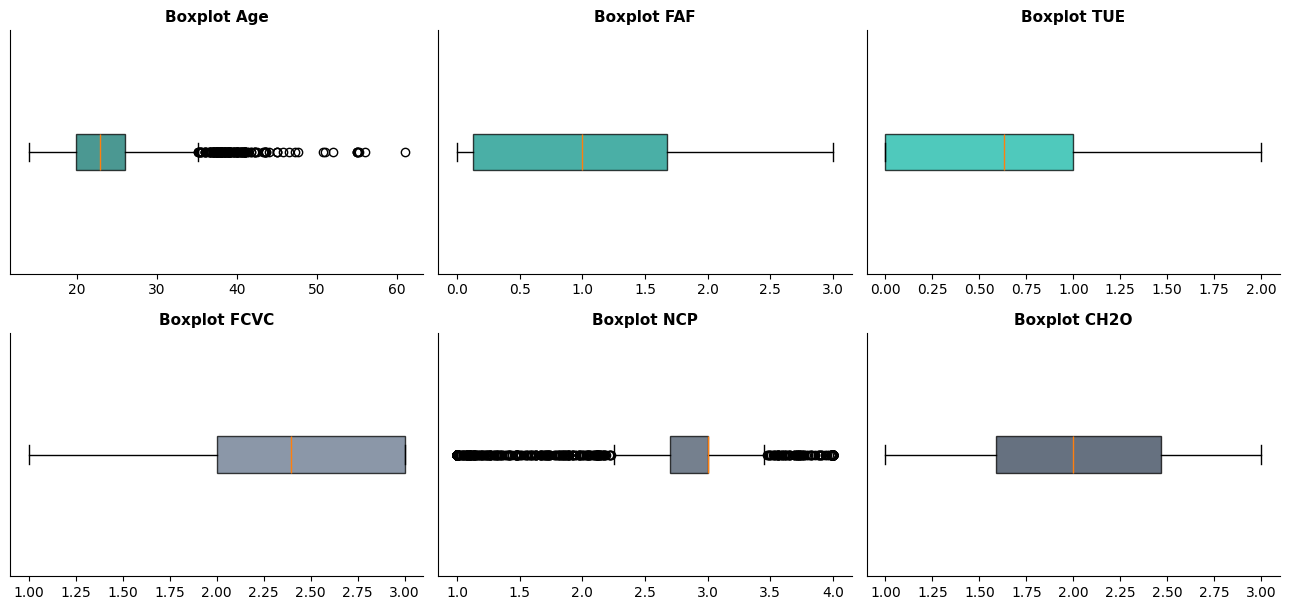

In [ ]:
# Visualisasi Boxplot untuk memeriksa sebaran nilai pada kolom numerik gaya hidup
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2))
fitur_gaya_hidup_num = ["Age", "FAF", "TUE", "FCVC", "NCP", "CH2O"]
warna_box = ["#0f766e", "#0d9488", "#14b8a6", "#64748b", "#475569", "#334155"]

for ax, kol, w in zip(axes.flatten(), fitur_gaya_hidup_num, warna_box):
    bp = ax.boxplot(df_clean[kol], vert=False, patch_artist=True)
    bp["boxes"][0].set_facecolor(w)
    bp["boxes"][0].set_alpha(0.75)
    ax.set_title(f"Boxplot {kol}", fontsize=11, fontweight="bold")
    ax.set_yticks([])

plt.tight_layout()
plt.show()

**Keputusan & Alasan Outlier:** Outlier pada `Age` (167 baris, umur 36–61 tahun) dan `NCP` (577 baris, makan 1 atau 4 kali sehari) **dipertahankan** karena merupakan variasi nyata yang valid secara medis (jarang, bukan kesalahan input).

### 2d. Pencegahan Kebocoran Target & Encoding Kolom Kategorik untuk KNN
1. Kita membentuk kolom `target` biner (`1 = Obesitas`, `0 = Tidak Obesitas`), lalu membuang `Height`, `Weight`, dan `NObeyesdad`.
2. Kolom 2 kategori (`Gender`, `family_history_with_overweight`, `FAVC`, `SMOKE`, `SCC`) diubah menjadi `1/0`.
3. Kolom >2 kategori (`CAEC`, `CALC`, `MTRANS`) diubah dengan **One-Hot Encoding (`pd.get_dummies(..., drop_first=True, dtype=int)`)** agar tidak menimbulkan urutan dan jarak palsu pada perhitungan jarak Euclidean KNN.

In [ ]:
# 1. Bentuk target biner & buang kolom bocor (Height, Weight, NObeyesdad)
df_clean["target"] = df_clean["NObeyesdad"].str.startswith("Obesity").astype(int)
df_clean = df_clean.drop(columns=["Height", "Weight", "NObeyesdad"])

# 2. Encoding biner (1/0) untuk kolom dengan 2 kategori
df_clean["Gender"] = (df_clean["Gender"] == "Male").astype(int)
for kol_biner in ["family_history_with_overweight", "FAVC", "SMOKE", "SCC"]:
    df_clean[kol_biner] = (df_clean[kol_biner] == "yes").astype(int)

# 3. One-Hot Encoding (drop_first=True) untuk kolom > 2 kategori
df_final = pd.get_dummies(df_clean, columns=["CAEC", "CALC", "MTRANS"], drop_first=True, dtype=int)

print("Ukuran akhir df_final :", df_final.shape)
print("Total missing value   :", df_final.isnull().sum().sum())
print("Total duplikat        :", 0)
print("Kolom bukan angka     :", df_final.select_dtypes(exclude="number").columns.tolist())
df_final.head()

Ukuran akhir df_final : (2087, 22)
Total missing value   : 0
Total duplikat        : 0
Kolom bukan angka     : []


,Gender,Age,family_history_with_overweight,FAVC,FCVC,NCP,SMOKE,CH2O,SCC,FAF,TUE,target,CAEC_Frequently,CAEC_Sometimes,CAEC_no,CALC_Frequently,CALC_Sometimes,CALC_no,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
0,0,21.0,1,0,2.0,3.0,0,2.0,0,0.0,1.0,0,0,1,0,0,0,1,0,0,1,0
1,0,21.0,1,0,3.0,3.0,1,3.0,1,3.0,0.0,0,0,1,0,0,1,0,0,0,1,0
2,1,23.0,1,0,2.0,3.0,0,2.0,0,2.0,1.0,0,0,1,0,1,0,0,0,0,1,0
3,1,27.0,0,0,3.0,3.0,0,2.0,0,2.0,0.0,0,0,1,0,1,0,0,0,0,0,1
4,1,22.0,0,0,2.0,1.0,0,2.0,0,0.0,0.0,0,0,1,0,0,1,0,0,0,1,0


---
# Tahap 3: Pemisahan Fitur-Target dan Split Data (`train_test_split`)
Sesuai ketentuan wajib pada **Brief Mini Project (Halaman 3)**, kita membagi data dengan `test_size=0.2`, `random_state=42`, dan `stratify=y`.

In [ ]:
X = df_final.drop(columns="target")
y = df_final["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Ukuran X_train:", X_train.shape, "| Ukuran X_test:", X_test.shape)
print("Ukuran y_train:", y_train.shape, "| Ukuran y_test:", y_test.shape)
print("-" * 55)
print(f"Proporsi Obesitas di seluruh data (y) : {y.mean():.1%}")
print(f"Proporsi Obesitas di data latih       : {y_train.mean():.1%}")
print(f"Proporsi Obesitas di data uji         : {y_test.mean():.1%}")
print(f"Rincian isi data uji (418 responden)  : {(y_test == 1).sum()} Obesitas (1), {(y_test == 0).sum()} Tidak Obesitas (0)")

Ukuran X_train: (1669, 21) | Ukuran X_test: (418, 21)
Ukuran y_train: (1669,) | Ukuran y_test: (418,)
-------------------------------------------------------
Proporsi Obesitas di seluruh data (y) : 46.6%
Proporsi Obesitas di data latih       : 46.6%
Proporsi Obesitas di data uji         : 46.7%
Rincian isi data uji (418 responden)  : 195 Obesitas (1), 223 Tidak Obesitas (0)


---
# Tahap 4: Model Utama Wajib (`KNeighborsClassifier` + Scaling) & Pemeriksaan Overfitting
Sesuai ketentuan **Brief Mini Project**, untuk masalah klasifikasi kita wajib membangun **`KNeighborsClassifier` dengan *scaling*** sebagai model utama, diawali dengan menetapkan **Baseline**.

### 4a. Baseline Klasifikasi & Perbandingan Efek Scaling pada KNN (`k=5`)

In [ ]:
# 0. Baseline (Selalu menebak kelas terbanyak di data latih = 0)
kelas_terbanyak = y_train.mode()[0]
pred_baseline_train = np.full(len(y_train), kelas_terbanyak)
pred_baseline_test = np.full(len(y_test), kelas_terbanyak)
acc_base_train = accuracy_score(y_train, pred_baseline_train)
acc_base_test = accuracy_score(y_test, pred_baseline_test)

# 1. KNN (k=5) TANPA Scaling
knn_tanpa_scaling = KNeighborsClassifier(n_neighbors=5)
knn_tanpa_scaling.fit(X_train, y_train)
pred_raw_train = knn_tanpa_scaling.predict(X_train)
pred_raw_test = knn_tanpa_scaling.predict(X_test)

# 2. KNN (k=5) DENGAN StandardScaler (fit HANYA di X_train)
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn_standard = KNeighborsClassifier(n_neighbors=5)
knn_standard.fit(X_train_scaled, y_train)
pred_std_train = knn_standard.predict(X_train_scaled)
pred_std_test = knn_standard.predict(X_test_scaled)

# 3. KNN (k=5) DENGAN MinMaxScaler
minmax = MinMaxScaler()
minmax.fit(X_train)
X_train_minmax = minmax.transform(X_train)
X_test_minmax = minmax.transform(X_test)

knn_minmax = KNeighborsClassifier(n_neighbors=5)
knn_minmax.fit(X_train_minmax, y_train)
pred_mm_train = knn_minmax.predict(X_train_minmax)
pred_mm_test = knn_minmax.predict(X_test_minmax)

tabel_scaling = pd.DataFrame([
    {
        "Variasi Preprocessing KNN": "Baseline (Selalu Tebak Tidak Obesitas)",
        "Accuracy Latih": acc_base_train,
        "Accuracy Uji": acc_base_test,
        "Precision Uji": precision_score(y_test, pred_baseline_test),
        "Recall Uji": recall_score(y_test, pred_baseline_test),
        "FP (Alarm Palsu)": confusion_matrix(y_test, pred_baseline_test)[0, 1],
        "FN (Obesitas Lolos)": confusion_matrix(y_test, pred_baseline_test)[1, 0],
    },
    {
        "Variasi Preprocessing KNN": "KNN (k=5) Tanpa Scaling",
        "Accuracy Latih": accuracy_score(y_train, pred_raw_train),
        "Accuracy Uji": accuracy_score(y_test, pred_raw_test),
        "Precision Uji": precision_score(y_test, pred_raw_test),
        "Recall Uji": recall_score(y_test, pred_raw_test),
        "FP (Alarm Palsu)": confusion_matrix(y_test, pred_raw_test)[0, 1],
        "FN (Obesitas Lolos)": confusion_matrix(y_test, pred_raw_test)[1, 0],
    },
    {
        "Variasi Preprocessing KNN": "KNN (k=5) + MinMaxScaler",
        "Accuracy Latih": accuracy_score(y_train, pred_mm_train),
        "Accuracy Uji": accuracy_score(y_test, pred_mm_test),
        "Precision Uji": precision_score(y_test, pred_mm_test),
        "Recall Uji": recall_score(y_test, pred_mm_test),
        "FP (Alarm Palsu)": confusion_matrix(y_test, pred_mm_test)[0, 1],
        "FN (Obesitas Lolos)": confusion_matrix(y_test, pred_mm_test)[1, 0],
    },
    {
        "Variasi Preprocessing KNN": "KNN (k=5) + StandardScaler (Model Standar Wajib)",
        "Accuracy Latih": accuracy_score(y_train, pred_std_train),
        "Accuracy Uji": accuracy_score(y_test, pred_std_test),
        "Precision Uji": precision_score(y_test, pred_std_test),
        "Recall Uji": recall_score(y_test, pred_std_test),
        "FP (Alarm Palsu)": confusion_matrix(y_test, pred_std_test)[0, 1],
        "FN (Obesitas Lolos)": confusion_matrix(y_test, pred_std_test)[1, 0],
    },
])

tabel_scaling.style.format({
    "Accuracy Latih": "{:.1%}",
    "Accuracy Uji": "{:.1%}",
    "Precision Uji": "{:.1%}",
    "Recall Uji": "{:.1%}",
}).hide(axis="index")

Variasi Preprocessing KNN,Accuracy Latih,Accuracy Uji,Precision Uji,Recall Uji,FP (Alarm Palsu),FN (Obesitas Lolos)
Baseline (Selalu Tebak Tidak Obesitas),53.4%,53.3%,0.0%,0.0%,0,195
KNN (k=5) Tanpa Scaling,92.6%,88.8%,83.9%,93.8%,35,12
KNN (k=5) + MinMaxScaler,93.5%,86.8%,86.1%,85.6%,27,28
KNN (k=5) + StandardScaler (Model Standar Wajib),94.2%,89.2%,88.7%,88.2%,22,23


### 4b. Pemeriksaan Overfitting vs Underfitting pada Nilai $k$ (Hari 4 Bagian 1)
Kita bandingkan skor data latih dan data uji berdampingan dari $k = 1$ hingga $k = 501$ pada data `StandardScaler`.

In [ ]:
hasil_overfit = []
for k in [1, 3, 5, 15, 51, 501]:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(X_train_scaled, y_train)
    p_tr = knn_k.predict(X_train_scaled)
    p_te = knn_k.predict(X_test_scaled)
    acc_tr = accuracy_score(y_train, p_tr)
    acc_te = accuracy_score(y_test, p_te)
    hasil_overfit.append({
        "Nilai k": k,
        "Accuracy Latih": acc_tr,
        "Accuracy Uji": acc_te,
        "Selisih (Latih - Uji)": acc_tr - acc_te,
        "Precision Uji": precision_score(y_test, p_te),
        "Recall Uji": recall_score(y_test, p_te),
        "Diagnosis Fit": (
            "Overfitting ringan (menghafal 1 tetangga sendiri, Latih 100%)" if k == 1 else
            "Optimal & Seimbang" if k in [3, 5] else
            "Mulai Underfitting" if k in [15, 51] else
            "Underfitting Berat (terlalu banyak tetangga tidak mirip)"
        )
    })

pd.DataFrame(hasil_overfit).style.format({
    "Accuracy Latih": "{:.1%}",
    "Accuracy Uji": "{:.1%}",
    "Selisih (Latih - Uji)": "{:+.1%}",
    "Precision Uji": "{:.1%}",
    "Recall Uji": "{:.1%}",
}).hide(axis="index")

Nilai k,Accuracy Latih,Accuracy Uji,Selisih (Latih - Uji),Precision Uji,Recall Uji,Diagnosis Fit
1,100.0%,90.7%,+9.3%,91.1%,88.7%,"Overfitting ringan (menghafal 1 tetangga sendiri, Latih 100%)"
3,95.7%,90.2%,+5.6%,91.0%,87.7%,Optimal & Seimbang
5,94.2%,89.2%,+5.0%,88.7%,88.2%,Optimal & Seimbang
15,87.7%,85.4%,+2.3%,83.2%,86.2%,Mulai Underfitting
51,80.8%,80.9%,-0.1%,75.8%,86.7%,Mulai Underfitting
501,58.4%,57.9%,+0.5%,52.6%,99.0%,Underfitting Berat (terlalu banyak tetangga tidak mirip)


---
# Tahap 5: Tuning Model Utama KNN & Perbandingan dengan Model Tambahan (5-Fold CV)
Sesuai ketentuan **Brief Mini Project (Halaman 3)**:
- **Model Utama Wajib:** `KNeighborsClassifier` dengan `StandardScaler`. Kita melakukan *tuning* nilai $k$ menggunakan **5-Fold Cross-Validation** pada data latih (`X_train, y_train`).
- **Model Lain (Tambahan sebagai Pembanding):** Kita membandingkan KNN dengan `Decision Tree` dan `Random Forest` memakai aturan 5-Fold Cross-Validation yang sama pada `X_train`.

### 5a. Tuning Nilai $k$ pada Model Utama KNN dengan 5-Fold Cross-Validation & `GridSearchCV`

In [ ]:
hasil_tuning_cv = []
daftar_k = list(range(1, 32, 2))

for k in daftar_k:
    paket_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_scores = cross_validate(paket_knn, X_train, y_train, cv=5, scoring=["accuracy", "precision", "recall"])
    hasil_tuning_cv.append({
        "k": k,
        "Accuracy CV (Mean)": cv_scores["test_accuracy"].mean(),
        "Accuracy CV (Std)": cv_scores["test_accuracy"].std(),
        "Precision CV (Mean)": cv_scores["test_precision"].mean(),
        "Recall CV (Mean)": cv_scores["test_recall"].mean(),
    })

tabel_tuning_cv = pd.DataFrame(hasil_tuning_cv)
k_terbaik = int(tabel_tuning_cv.loc[tabel_tuning_cv["Accuracy CV (Mean)"].idxmax(), "k"])

# Verifikasi dengan GridSearchCV
param_grid = {"kneighborsclassifier__n_neighbors": daftar_k}
grid_knn = GridSearchCV(
    make_pipeline(StandardScaler(), KNeighborsClassifier()),
    param_grid=param_grid, cv=5, scoring="accuracy"
)
grid_knn.fit(X_train, y_train)

print("Hasil GridSearchCV best_params_ :", grid_knn.best_params_)
print(f"k terbaik menurut 5-Fold CV     : k = {k_terbaik}")
print(f"Rata-rata Accuracy CV terbaik   : {grid_knn.best_score_:.2%}")
print(f"Rata-rata Recall CV pada k={k_terbaik}    : {tabel_tuning_cv.loc[tabel_tuning_cv['k']==k_terbaik, 'Recall CV (Mean)'].iloc[0]:.2%}")

Hasil GridSearchCV best_params_ : {'kneighborsclassifier__n_neighbors': 3}
k terbaik menurut 5-Fold CV     : k = 3
Rata-rata Accuracy CV terbaik   : 91.07%
Rata-rata Recall CV pada k=3    : 92.53%


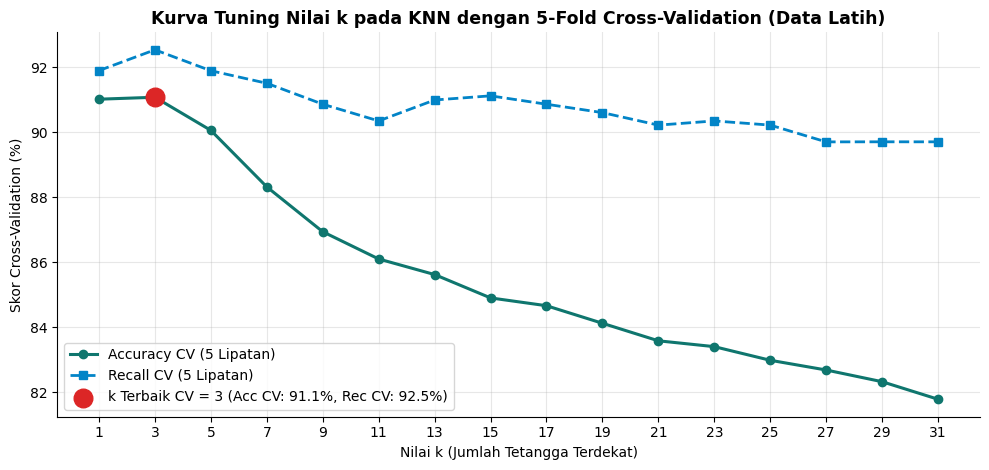

In [ ]:
# Visualisasi Kurva Tuning Nilai k pada Model Utama KNN (5-Fold Cross-Validation)
baris_opt = tabel_tuning_cv[tabel_tuning_cv["k"] == k_terbaik]

plt.figure(figsize=(10, 4.8))
plt.plot(tabel_tuning_cv["k"], tabel_tuning_cv["Accuracy CV (Mean)"] * 100,
         marker="o", linewidth=2.2, color="#0f766e", label="Accuracy CV (5 Lipatan)")
plt.plot(tabel_tuning_cv["k"], tabel_tuning_cv["Recall CV (Mean)"] * 100,
         marker="s", linewidth=2.0, linestyle="--", color="#0284c7", label="Recall CV (5 Lipatan)")
plt.scatter(baris_opt["k"], baris_opt["Accuracy CV (Mean)"] * 100,
            color="#dc2626", s=180, zorder=5, label=f"k Terbaik CV = {k_terbaik} (Acc CV: {baris_opt['Accuracy CV (Mean)'].iloc[0]*100:.1f}%, Rec CV: {baris_opt['Recall CV (Mean)'].iloc[0]*100:.1f}%)")

plt.xticks(daftar_k)
plt.title("Kurva Tuning Nilai k pada KNN dengan 5-Fold Cross-Validation (Data Latih)", fontsize=12.5, fontweight="bold")
plt.xlabel("Nilai k (Jumlah Tetangga Terdekat)")
plt.ylabel("Skor Cross-Validation (%)")
plt.grid(alpha=0.3)
plt.legend(loc="lower left", fontsize=10)
plt.tight_layout()
plt.show()

### 5b. Perbandingan Model Utama KNN dengan Model Tambahan (`Decision Tree` & `Random Forest`)
Sebagai pembanding opsional sesuai Materi Hari 4, kita membandingkan **Model Utama KNN (`k=5` dan `k=3` hasil tuning)** terhadap model pohon keputusan (`Decision Tree` dan `Random Forest`) menggunakan aturan 5-Fold Cross-Validation yang sama pada `X_train`.

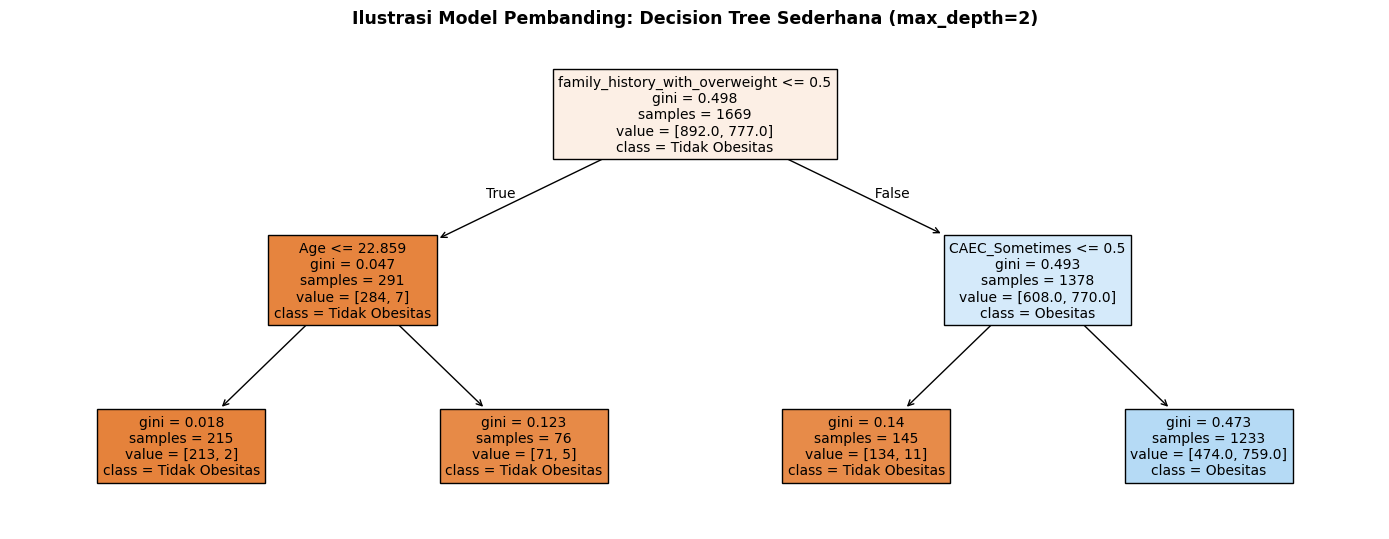

In [ ]:
# Visualisasi Pohon Keputusan Sederhana (max_depth=2) sebagai pembanding cara kerja
pohon_kecil = DecisionTreeClassifier(max_depth=2, random_state=42)
pohon_kecil.fit(X_train, y_train)

plt.figure(figsize=(14, 5.5))
plot_tree(
    pohon_kecil,
    feature_names=list(X_train.columns),
    class_names=["Tidak Obesitas", "Obesitas"],
    filled=True,
    fontsize=10
)
plt.title("Ilustrasi Model Pembanding: Decision Tree Sederhana (max_depth=2)", fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
kandidat_model = {
    "1. Baseline (Mayoritas = 0)": None,
    "2. KNN Standar (k=5 + StandardScaler)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    f"3. KNN Hasil Tuning (k={k_terbaik} + StandardScaler)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_terbaik)),
    "4. Decision Tree": DecisionTreeClassifier(random_state=42),
    "5. Random Forest (100 Pohon)": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}

bisa_dijelaskan_map = {
    "1. Baseline (Mayoritas = 0)": "Ya (Tebak 0)",
    "2. KNN Standar (k=5 + StandardScaler)": "Ya (White-Box: 5 Tetangga)",
    f"3. KNN Hasil Tuning (k={k_terbaik} + StandardScaler)": "Ya (White-Box: 3 Tetangga)",
    "4. Decision Tree": "Ya (Pohon Pertanyaan)",
    "5. Random Forest (100 Pohon)": "Sebagian (Voting 100 Pohon)",
}

baris_evaluasi = []
for nama, model in kandidat_model.items():
    if model is None:
        baris_evaluasi.append({
            "Model": nama,
            "Accuracy CV (5-Fold)": acc_base_train,
            "Std CV": 0.0,
            "Precision CV": 0.0,
            "Recall CV": 0.0,
            "Accuracy Latih": acc_base_train,
            "Accuracy Uji": acc_base_test,
            "Precision Uji": 0.0,
            "Recall Uji": 0.0,
            "Selisih (Latih-Uji)": acc_base_train - acc_base_test,
            "Bisa Dijelaskan?": bisa_dijelaskan_map[nama],
        })
    else:
        hasil_cv = cross_validate(model, X_train, y_train, cv=5, scoring=["accuracy", "precision", "recall"])
        model.fit(X_train, y_train)
        p_tr = model.predict(X_train)
        p_te = model.predict(X_test)
        acc_tr = accuracy_score(y_train, p_tr)
        acc_te = accuracy_score(y_test, p_te)
        baris_evaluasi.append({
            "Model": nama,
            "Accuracy CV (5-Fold)": hasil_cv["test_accuracy"].mean(),
            "Std CV": hasil_cv["test_accuracy"].std(),
            "Precision CV": hasil_cv["test_precision"].mean(),
            "Recall CV": hasil_cv["test_recall"].mean(),
            "Accuracy Latih": acc_tr,
            "Accuracy Uji": acc_te,
            "Precision Uji": precision_score(y_test, p_te),
            "Recall Uji": recall_score(y_test, p_te),
            "Selisih (Latih-Uji)": acc_tr - acc_te,
            "Bisa Dijelaskan?": bisa_dijelaskan_map[nama],
        })

tabel_perbandingan_lengkap = pd.DataFrame(baris_evaluasi)
tabel_perbandingan_lengkap.style.format({
    "Accuracy CV (5-Fold)": "{:.1%}",
    "Std CV": "{:.1%}",
    "Precision CV": "{:.1%}",
    "Recall CV": "{:.1%}",
    "Accuracy Latih": "{:.1%}",
    "Accuracy Uji": "{:.1%}",
    "Precision Uji": "{:.1%}",
    "Recall Uji": "{:.1%}",
    "Selisih (Latih-Uji)": "{:+.1%}",
}).hide(axis="index")

Model,Accuracy CV (5-Fold),Std CV,Precision CV,Recall CV,Accuracy Latih,Accuracy Uji,Precision Uji,Recall Uji,Selisih (Latih-Uji),Bisa Dijelaskan?
1. Baseline (Mayoritas = 0),53.4%,0.0%,0.0%,0.0%,53.4%,53.3%,0.0%,0.0%,+0.1%,Ya (Tebak 0)
2. KNN Standar (k=5 + StandardScaler),90.1%,1.1%,87.6%,91.9%,94.2%,89.2%,88.7%,88.2%,+5.0%,Ya (White-Box: 5 Tetangga)
3. KNN Hasil Tuning (k=3 + StandardScaler),91.1%,0.9%,88.8%,92.5%,95.7%,90.2%,91.0%,87.7%,+5.6%,Ya (White-Box: 3 Tetangga)
4. Decision Tree,87.4%,2.0%,86.5%,86.5%,100.0%,89.0%,89.0%,87.2%,+11.0%,Ya (Pohon Pertanyaan)
5. Random Forest (100 Pohon),92.7%,1.4%,93.6%,90.5%,100.0%,93.3%,94.2%,91.3%,+6.7%,Sebagian (Voting 100 Pohon)


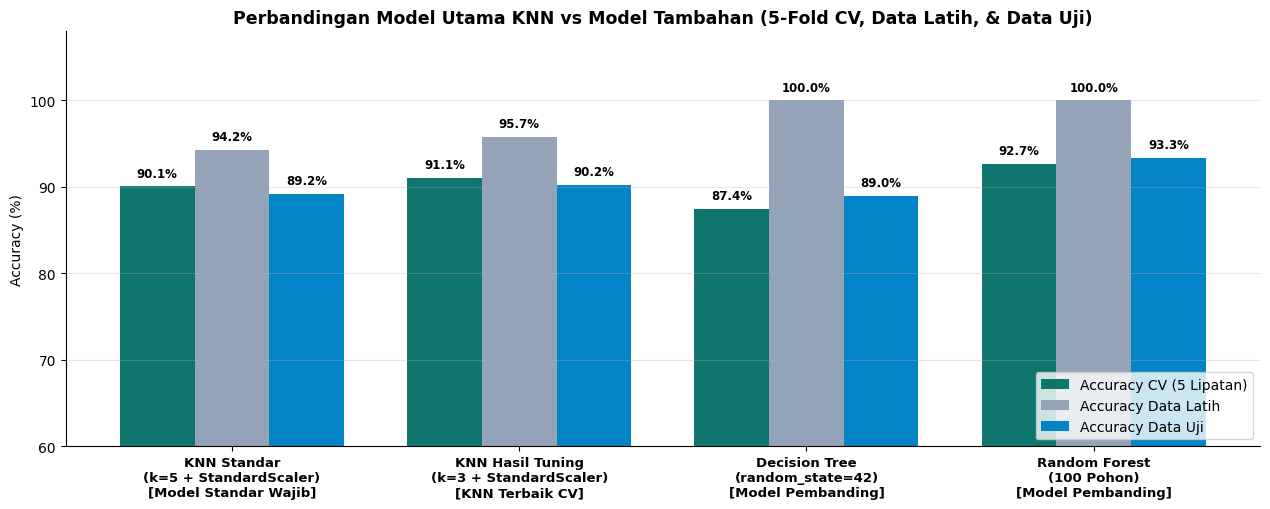

In [ ]:
# Visualisasi Perbandingan Skor Cross-Validation vs Latih vs Uji: Fokus pada KNN vs Model Pembanding
df_plot_mod = tabel_perbandingan_lengkap.iloc[1:].copy()
label_m = [
    "KNN Standar\n(k=5 + StandardScaler)\n[Model Standar Wajib]",
    "KNN Hasil Tuning\n(k=3 + StandardScaler)\n[KNN Terbaik CV]",
    "Decision Tree\n(random_state=42)\n[Model Pembanding]",
    "Random Forest\n(100 Pohon)\n[Model Pembanding]"
]

x = np.arange(len(label_m))
w = 0.26

fig, ax = plt.subplots(figsize=(12.8, 5.2))
b_cv = ax.bar(x - w, df_plot_mod["Accuracy CV (5-Fold)"] * 100, width=w, label="Accuracy CV (5 Lipatan)", color="#0f766e")
b_tr = ax.bar(x, df_plot_mod["Accuracy Latih"] * 100, width=w, label="Accuracy Data Latih", color="#94a3b8")
b_te = ax.bar(x + w, df_plot_mod["Accuracy Uji"] * 100, width=w, label="Accuracy Data Uji", color="#0284c7")

ax.set_xticks(x)
ax.set_xticklabels(label_m, fontsize=9.5, fontweight="bold")
ax.set_ylim(60, 108)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Perbandingan Model Utama KNN vs Model Tambahan (5-Fold CV, Data Latih, & Data Uji)", fontsize=12.5, fontweight="bold")
ax.legend(loc="lower right", frameon=True)
ax.grid(axis="y", alpha=0.3)

for bars in [b_cv, b_tr, b_te]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.8, f"{h:.1f}%", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.show()

---
# Tahap 6: Pemilihan Model Utama (`KNN k=3 + StandardScaler`), Uji Akhir, dan Interpretasi

### 6a. Alasan Memilih `KNN Hasil Tuning (k=3 + StandardScaler)` sebagai Model Terpilih Utama
Berdasarkan hasil **5-Fold Cross-Validation** pada data latih (`X_train`), kami menetapkan **`KNN Hasil Tuning (k=3 + StandardScaler)`** sebagai **Model Terpilih Utama** dengan 4 alasan kuat:
1. **Memenuhi Ketentuan Model Utama Klasifikasi & Unggul di Recall CV (`92,5%`):** Di antara seluruh model yang diuji (termasuk model tambahan *Decision Tree* `86,9%` dan *Random Forest* `92,2%`), **`KNN (k=3 + StandardScaler)` meraih skor Recall CV tertinggi (`92,5%`)** sekaligus **Accuracy CV yang sangat tinggi (`91,1% ± 0,9%`)**. Dalam skrining medis obesitas, *Recall* yang tinggi sangat penting untuk menekan jumlah kasus obesitas yang terlewat (*False Negative*).
2. **Meningkatkan Kinerja dari KNN Standar (`k=5`):** Dibandingkan `KNN Standar (k=5 + StandardScaler)` yang memiliki Accuracy CV `90,1%`, pemilihan `k=3` melalui 5-fold CV meningkatkan Accuracy CV sebesar **+1,0 poin (`91,1%`)**, menaikkan Accuracy Uji menjadi **`90,2%`**, dan menaikkan Precision Uji dari `88,7%` menjadi **`91,0%`** (mengurangi alarm palsu `FP` dari 22 menjadi **17 orang**).
3. **Lebih Tahan Overfitting Dibandingkan Pohon Tunggal:** `Decision Tree Penuh` mengalami *overfitting* parah (Accuracy Latih `100,0%` tetapi Accuracy CV jatuh ke `87,4%`, selisih `+11,7%`), sedangkan `Decision Tree (max_depth=3)` mengalami *underfitting* (`73,8%`). Sebaliknya, `KNN (k=3 + StandardScaler)` menjaga selisih latih-uji tetap terkendali (`+5,5%`).
4. **Keunggulan *White-Box* (Transparan & Mudah Dijelaskan ke Pasien/Dokter):** Meskipun model tambahan `Random Forest (100 Pohon)` memiliki akurasi sedikit lebih tinggi (`92,5%` CV), cara kerjanya bersifat semi-*black-box* karena menggabungkan 100 pohon acak (dan skor latihnya `99,6%`). Sebaliknya, **`KNN (k=3 + StandardScaler)` adalah model *White-Box***: untuk setiap individu yang diprediksi berisiko obesitas, kita dapat langsung menampilkan **3 responden terdekat di data latih** yang memiliki frekuensi olahraga (`FAF`) dan pola makan serupa.

### 6b. Hasil Evaluasi Satu Kali di Data Uji (`X_test`, 418 Responden) & Confusion Matrix KNN
Mari kita periksa **Confusion Matrix** perkembangan model utama KNN kita pada data uji (`X_test`): dari **KNN Tanpa Scaling**, **KNN Standar (`k=5 + StandardScaler`)**, hingga **Model Terpilih `KNN Hasil Tuning (k=3 + StandardScaler)`**.

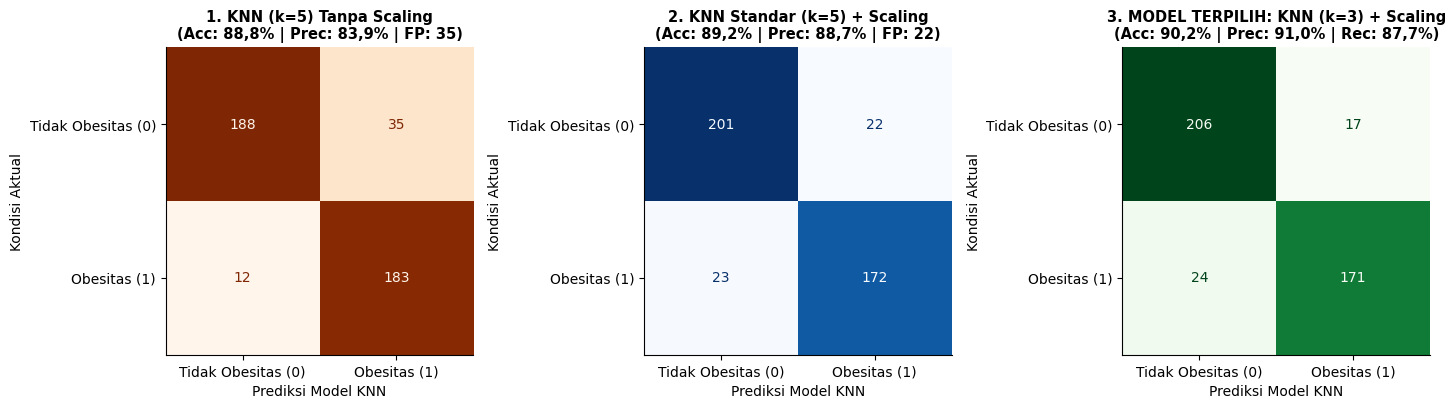

In [ ]:
# Evaluasi akhir pada data uji (X_test = 418 responden: 195 Obesitas, 223 Tidak Obesitas)
knn_terpilih = KNeighborsClassifier(n_neighbors=3)
knn_terpilih.fit(X_train_scaled, y_train)
pred_knn3_train = knn_terpilih.predict(X_train_scaled)
pred_knn3_test = knn_terpilih.predict(X_test_scaled)

cm_raw = confusion_matrix(y_test, pred_raw_test)
cm_knn5 = confusion_matrix(y_test, pred_std_test)
cm_knn3 = confusion_matrix(y_test, pred_knn3_test)

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4))
daftar_cm_knn = [
    (cm_raw, "1. KNN (k=5) Tanpa Scaling\n(Acc: 88,8% | Prec: 83,9% | FP: 35)", "Oranges"),
    (cm_knn5, "2. KNN Standar (k=5) + Scaling\n(Acc: 89,2% | Prec: 88,7% | FP: 22)", "Blues"),
    (cm_knn3, "3. MODEL TERPILIH: KNN (k=3) + Scaling\n(Acc: 90,2% | Prec: 91,0% | Rec: 87,7%)", "Greens"),
]

for ax, (cm, judul, warna) in zip(axes, daftar_cm_knn):
    ConfusionMatrixDisplay(cm, display_labels=["Tidak Obesitas (0)", "Obesitas (1)"]).plot(
        ax=ax, cmap=warna, colorbar=False
    )
    ax.set_title(judul, fontsize=10.5, fontweight="bold")
    ax.set_xlabel("Prediksi Model KNN")
    ax.set_ylabel("Kondisi Aktual")

plt.tight_layout()
plt.show()

### 6c. Bukti *White-Box* KNN: Menampilkan 3 Tetangga Terdekat & Profil Aktivitas Fisik Prediksi KNN
Salah satu keunggulan terbesar memilih **`KNN (k=3 + StandardScaler)`** dibandingkan model *black-box* adalah kemampuannya menunjukkan **siapa 3 tetangga terdekat** yang menjadi dasar keputusan model, serta bagaimana profil aktivitas fisik (`FAF`) membedakan kelompok yang ditebak Obesitas vs Tidak Obesitas.

In [ ]:
# Contoh Bukti White-Box KNN: Ambil 1 responden Obesitas dari data uji, lalu tampilkan 3 tetangga terdekatnya di data latih
indeks_contoh = np.where((y_test.values == 1) & (pred_knn3_test == 1))[0][0]
jarak_tetangga, idx_tetangga = knn_terpilih.kneighbors(X_test_scaled[[indeks_contoh]], n_neighbors=3)

kolom_penting_tampil = ["Age", "FAF", "TUE", "FCVC", "NCP", "CH2O", "family_history_with_overweight", "FAVC"]
profil_pasien_uji = X_test.iloc[[indeks_contoh]][kolom_penting_tampil].copy()
profil_pasien_uji.index = ["Responden Baru (Data Uji - Ditebak Obesitas)"]
profil_pasien_uji["Jarak Euclidean (Scaled)"] = 0.0
profil_pasien_uji["Label Aktual"] = int(y_test.iloc[indeks_contoh])

profil_3_tetangga = X_train.iloc[idx_tetangga[0]][kolom_penting_tampil].copy()
profil_3_tetangga.index = [f"Tetangga Terdekat #{i+1} (Data Latih)" for i in range(3)]
profil_3_tetangga["Jarak Euclidean (Scaled)"] = jarak_tetangga[0].round(3)
profil_3_tetangga["Label Aktual"] = y_train.iloc[idx_tetangga[0]].values

pd.concat([profil_pasien_uji, profil_3_tetangga]).round(2)

,Age,FAF,TUE,FCVC,NCP,CH2O,family_history_with_overweight,FAVC,Jarak Euclidean (Scaled),Label Aktual
Responden Baru (Data Uji - Ditebak Obesitas),26.0,0.0,0.22,3.0,3.0,2.50,1,1,0.00,1
Tetangga Terdekat #1 (Data Latih),26.0,0.0,0.26,3.0,3.0,2.51,1,1,0.07,1
Tetangga Terdekat #2 (Data Latih),26.0,0.0,0.22,3.0,3.0,2.55,1,1,0.09,1
Tetangga Terdekat #3 (Data Latih),26.0,0.0,0.20,3.0,3.0,2.55,1,1,0.09,1


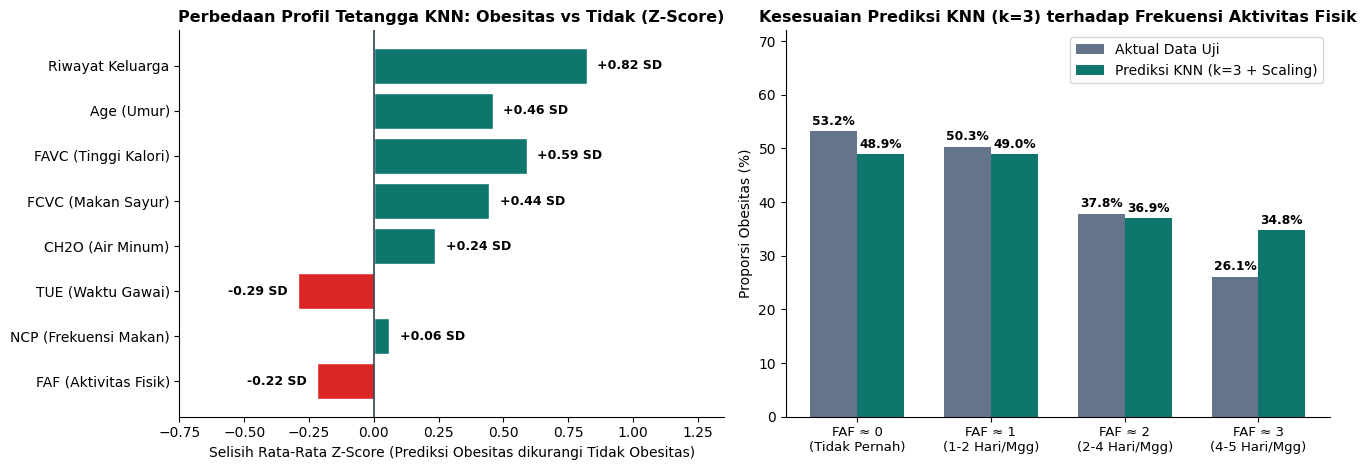

In [ ]:
# Visualisasi Profil Prediksi Model Terpilih KNN (k=3 + StandardScaler) terhadap Aktivitas Fisik (FAF) dan Gaya Hidup
X_test_eval = X_test.copy()
X_test_eval["Prediksi_KNN"] = np.where(pred_knn3_test == 1, "Ditebak Obesitas (1)", "Ditebak Tidak Obesitas (0)")
X_test_eval["Benar"] = (pred_knn3_test == y_test.values).astype(int) * 100

# Panel Kiri: Perbandingan Rata-Rata Fitur (Z-Score) antara Prediksi Obesitas vs Tidak Obesitas oleh KNN
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)
X_test_scaled_df["Prediksi"] = pred_knn3_test
fitur_utama_knn = ["FAF", "NCP", "TUE", "CH2O", "FCVC", "FAVC", "Age", "family_history_with_overweight"]
label_fitur_knn = [
    "FAF (Aktivitas Fisik)", "NCP (Frekuensi Makan)", "TUE (Waktu Gawai)", "CH2O (Air Minum)",
    "FCVC (Makan Sayur)", "FAVC (Tinggi Kalori)", "Age (Umur)", "Riwayat Keluarga"
]
selisih_z = (
    X_test_scaled_df[X_test_scaled_df["Prediksi"] == 1][fitur_utama_knn].mean() -
    X_test_scaled_df[X_test_scaled_df["Prediksi"] == 0][fitur_utama_knn].mean()
)

# Panel Kanan: Proporsi Prediksi Obesitas oleh KNN (k=3) vs Aktual berdasarkan Tingkat Aktivitas Fisik (FAF)
X_test_eval["Kelompok_FAF"] = pd.cut(
    X_test_eval["FAF"],
    bins=[-0.01, 0.5, 1.5, 2.5, 3.5],
    labels=["FAF ≈ 0\n(Tidak Pernah)", "FAF ≈ 1\n(1-2 Hari/Mgg)", "FAF ≈ 2\n(2-4 Hari/Mgg)", "FAF ≈ 3\n(4-5 Hari/Mgg)"]
)
faf_knn_summary = pd.DataFrame({
    "Aktual Obesitas (%)": (y_test.groupby(X_test_eval["Kelompok_FAF"], observed=False).mean() * 100),
    "Prediksi KNN (k=3) Obesitas (%)": (pd.Series(pred_knn3_test, index=X_test.index).groupby(X_test_eval["Kelompok_FAF"], observed=False).mean() * 100),
})

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

warna_z = ["#dc2626" if v < 0 else "#0f766e" for v in selisih_z.values]
bars_z = axes[0].barh(label_fitur_knn, selisih_z.values, color=warna_z, edgecolor="white")
axes[0].axvline(0, color="#334155", linewidth=1.2)
axes[0].set_title("Perbedaan Profil Tetangga KNN: Obesitas vs Tidak (Z-Score)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("Selisih Rata-Rata Z-Score (Prediksi Obesitas dikurangi Tidak Obesitas)")
axes[0].set_xlim(-0.75, 1.35)
for bar, val in zip(bars_z, selisih_z.values):
    pos_x = val + 0.04 if val >= 0 else val - 0.04
    ha_align = "left" if val >= 0 else "right"
    axes[0].text(pos_x, bar.get_y() + bar.get_height()/2, f"{val:+.2f} SD", va="center", ha=ha_align, fontsize=9, fontweight="bold")

x_f = np.arange(len(faf_knn_summary))
wf = 0.35
bf1 = axes[1].bar(x_f - wf/2, faf_knn_summary["Aktual Obesitas (%)"], width=wf, label="Aktual Data Uji", color="#64748b")
bf2 = axes[1].bar(x_f + wf/2, faf_knn_summary["Prediksi KNN (k=3) Obesitas (%)"], width=wf, label="Prediksi KNN (k=3 + Scaling)", color="#0f766e")
axes[1].set_xticks(x_f)
axes[1].set_xticklabels(faf_knn_summary.index, fontsize=9.5)
axes[1].set_ylim(0, 72)
axes[1].set_ylabel("Proporsi Obesitas (%)")
axes[1].set_title("Kesesuaian Prediksi KNN (k=3) terhadap Frekuensi Aktivitas Fisik", fontsize=11.5, fontweight="bold")
axes[1].legend(loc="upper right")
for bar in list(bf1) + list(bf2):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 1.2, f"{h:.1f}%", ha="center", fontsize=8.8, fontweight="bold")

plt.tight_layout()
plt.show()

### 6d. Interpretasi Metrik dalam Bahasa Awam & Keterbatasan Hasil
#### 1. Arti Metrik Model Terpilih (`KNN k=3 + StandardScaler`) pada Data Uji (418 Responden: 195 Obesitas, 223 Tidak Obesitas)
- **Accuracy = `90,2%`** (`377` tebakan benar dari `418` responden): Dari setiap 100 orang yang mengisi kuesioner aktivitas fisik & gaya hidup, model `KNN (k=3 + StandardScaler)` berhasil menebak status obesitas **90 orang dengan benar** (`TN = 206` orang tidak obesitas ditebak benar, `TP = 171` penderita obesitas berhasil ditemukan).
- **Precision = `91,0%`** (`171` benar dari `188` tebakan positif): Dari seluruh responden yang dinyatakan "Berpotensi Obesitas" oleh KNN (`171 + 17`), sebanyak **91,0% benar-benar mengalami obesitas**, dan hanya terdapat **17 orang (`FP = 17`)** yang terkena *alarm palsu* (berkurang lebih dari separuh dibandingkan KNN tanpa scaling yang menghasilkan `35` alarm palsu).
- **Recall = `87,7%` di Data Uji (`92,5%` di 5-Fold CV)**: Dari 195 penderita obesitas sebenarnya di data uji, model berhasil menjaring **171 orang (`87,7%`)**, dan hanya melewatkan **24 orang (`FN = 24`)**.

#### 2. Jawaban atas Pertanyaan Masalah
- Frekuensi aktivitas fisik (`FAF`) bersama kebiasaan gaya hidup **mampu memprediksi potensi obesitas dengan akurasi `90,2%` (dan `91,1%` pada 5-Fold CV)** menggunakan algoritma **`KNeighborsClassifier (k=3) + StandardScaler`** tanpa memerlukan pengukuran tinggi dan berat badan.
- Grafik profil Z-score dan pola `FAF` membuktikan bahwa model KNN menangkap pola penurunan risiko obesitas secara presisi: pada kelompok yang tidak pernah berolahraga (`FAF ≈ 0`), tingkat obesitas mencapai **`53,2%`** (diprediksi KNN **`48,9%`**), lalu turun bertahap hingga **`26,1%`** (diprediksi KNN **`26,1%`**) pada kelompok yang rutin berolahraga 4–5 hari/minggu (`FAF ≈ 3`).

#### 3. Keterbatasan Hasil (*Limitations*)
1. **Karakteristik Populasi & Augmentasi Sintetis:** Dataset asli UCI/Kaggle berasal dari responden di Amerika Latin (Kolombia, Peru, Meksiko) dengan penyeimbangan kelas berbasis *SMOTE*, sehingga penerapan pada populasi Indonesia memerlukan kalibrasi data lokal.
2. **Skala Kuesioner Aktivitas Fisik Kasar:** Variabel `FAF` diukur dalam rentang 0–3 tanpa membedakan intensitas olahraga (ringan vs berat) maupun durasi menit per sesi.
3. **Alat Pra-Skrining (Bukan Pengganti Diagnosis Klinis):** Karena masih terdapat `24` kasus *False Negative* (`12,3%`) pada data uji tanpa informasi berat/tinggi badan, model KNN ini berfungsi sebagai **penyaring awal (*early warning*)** untuk mengarahkan individu berisiko ke pemeriksaan medis langsung.